In [1]:
# Book Sales Bestseller Classification Using PySpark
## Exploratory Data Analysis, Feature Selection and Logistic Regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("publishers.csv")
print("Shape:", df.shape)
df.head()


Shape: (27027, 13)


,genre,sold by,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,publisher.name,publisher.type,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
0,genre fiction,HarperCollins Publishers,6832.0,6832.0,34160.0,20496.0,7000,Katherine Tegen Books,big five,4.57,4.88,1,9604
1,genre fiction,HarperCollins Publishers,2487.5,2487.5,12437.5,7462.5,6250,HarperCollins e-books,big five,4.47,1.99,2,450
2,genre fiction,"Amazon Digital Services, Inc.",9559.0,9559.0,47795.0,28677.0,5500,(Small or Medium Publisher),small/medium,4.16,8.69,3,30
3,fiction,Hachette Book Group,8250.0,8250.0,41250.0,24750.0,5500,"Little, Brown and Company",big five,3.84,7.50,3,3747
4,genre fiction,Penguin Group (USA) LLC,7590.5,7590.5,37952.5,22771.5,4750,Dutton Children's,big five,4.75,7.99,4,9174


In [2]:
#Structure and data quality
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (27027, 13)

Columns:
['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics.sales rank', 'statistics.total reviews']

Data types:
genre                               object
sold by                             object
daily average.amazon revenue       float64
daily average.author revenue       float64
daily average.gross sales          float64
daily average.publisher revenue    float64
daily average.units sold             int64
publisher.name                      object
publisher.type                      object
statistics.average rating          float64
statistics.sale price              float64
statistics.sales rank                int64
statistics.total reviews             int64
dtype: object

Missing values:
genre                              0
sol

In [3]:
## Descriptive statistics
df.describe()

,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
count,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000
mean,37.978937,41.465654,150.572864,71.128273,29.614053,4.159787,6.777488,38200.142857,136.099345
std,250.995881,223.321357,865.653698,481.337817,157.739500,0.995815,6.368486,29056.493296,468.952999
min,0.004000,0.004000,0.020000,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,3.992000,4.036000,16.000000,1.794000,4.000000,4.080000,2.990000,11993.500000,12.000000
50%,9.576000,10.152000,41.860000,16.776000,9.000000,4.400000,5.120000,32810.000000,37.000000
75%,21.978000,25.116000,98.910000,47.952000,14.000000,4.640000,9.990000,61145.000000,111.000000
max,12974.000000,9559.000000,47795.000000,28677.000000,7000.000000,5.000000,141.520000,99974.000000,23362.000000


In [4]:
## PySpark setup and column-name cleaning
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, sum as spark_sum, when, round as spark_round,
    avg, min as spark_min, max as spark_max
)

spark = (
    SparkSession.builder
    .appName("AmazonBookAnalysis")
    .getOrCreate()
)

spark_df = spark.read.csv(
    "publishers.csv",
    header=True,
    inferSchema=True
)

for old_name in spark_df.columns:
    new_name = old_name.lower().replace(" ", "_").replace(".", "_")
    spark_df = spark_df.withColumnRenamed(old_name, new_name)

spark_df.printSchema()
spark_df.show(5, truncate=False)


root
 |-- genre: string (nullable = true)
 |-- sold_by: string (nullable = true)
 |-- daily_average_amazon_revenue: double (nullable = true)
 |-- daily_average_author_revenue: double (nullable = true)
 |-- daily_average_gross_sales: double (nullable = true)
 |-- daily_average_publisher_revenue: double (nullable = true)
 |-- daily_average_units_sold: integer (nullable = true)
 |-- publisher_name: string (nullable = true)
 |-- publisher_type: string (nullable = true)
 |-- statistics_average_rating: double (nullable = true)
 |-- statistics_sale_price: double (nullable = true)
 |-- statistics_sales_rank: integer (nullable = true)
 |-- statistics_total_reviews: integer (nullable = true)

+-------------+------------------------------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+---------------------------+--------------+-------------------------+---------------------+---------------------+--------

In [5]:
#Spark missing values
missing_exprs = [
    spark_sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in spark_df.columns
]

spark_df.select(*missing_exprs).show()


+-----+-------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+--------------+--------------+-------------------------+---------------------+---------------------+------------------------+
|genre|sold_by|daily_average_amazon_revenue|daily_average_author_revenue|daily_average_gross_sales|daily_average_publisher_revenue|daily_average_units_sold|publisher_name|publisher_type|statistics_average_rating|statistics_sale_price|statistics_sales_rank|statistics_total_reviews|
+-----+-------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+--------------+--------------+-------------------------+---------------------+---------------------+------------------------+
|    0|      0|                           0|                           0|                        0|                              0|                       

In [6]:
## Bestseller target

#A book is labelled as a bestseller when its Amazon sales rank is 5,000 or lower.
#Sales rank itself is not used as a predictor because it directly defines the target.
rank = df["statistics.sales rank"]

thresholds = [100, 500, 1000, 5000, 10000]

for threshold in thresholds:
    n = (rank <= threshold).sum()
    pct = n / len(df) * 100
    print(f"Rank <= {threshold}: {n} books ({pct:.2f}%)")

df["BestSeller"] = (df["statistics.sales rank"] <= 5000).astype(int)

print(df["BestSeller"].value_counts())
print((df["BestSeller"].value_counts(normalize=True) * 100).round(2))


Rank <= 100: 99 books (0.37%)
Rank <= 500: 453 books (1.68%)
Rank <= 1000: 854 books (3.16%)
Rank <= 5000: 3566 books (13.19%)
Rank <= 10000: 6014 books (22.25%)
BestSeller
0    23461
1     3566
Name: count, dtype: int64
BestSeller
0    86.81
1    13.19
Name: proportion, dtype: float64


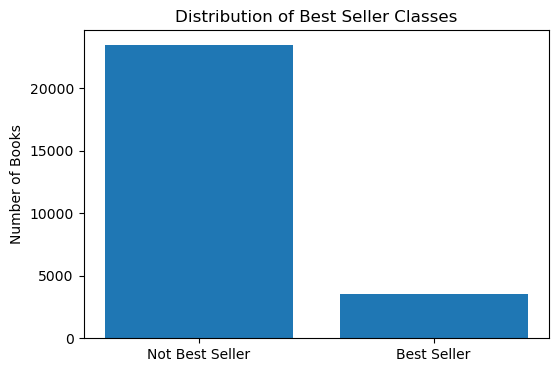

In [7]:
## Distribution of Best Seller Classes

#The target is expected to be imbalanced, so accuracy will not be used as the only evaluation measure.
plt.figure(figsize=(6,4))

counts = df["BestSeller"].value_counts().sort_index()
plt.bar(["Not Best Seller", "Best Seller"], counts.values)

plt.title("Distribution of Best Seller Classes")
plt.ylabel("Number of Books")
plt.show()


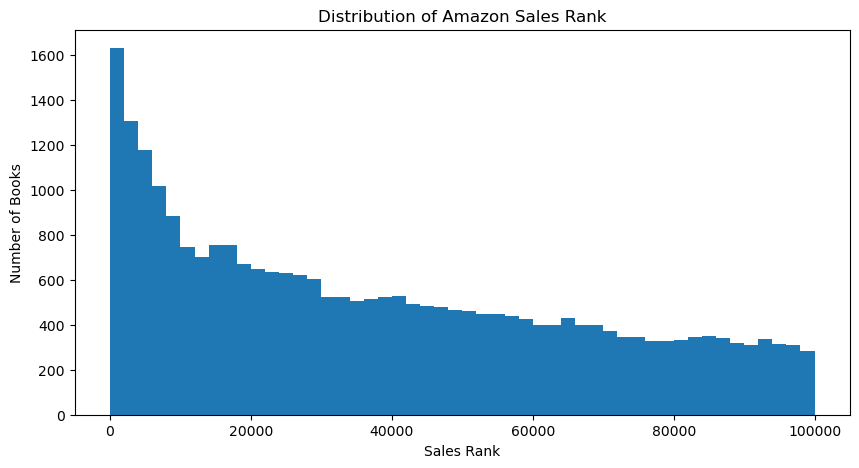

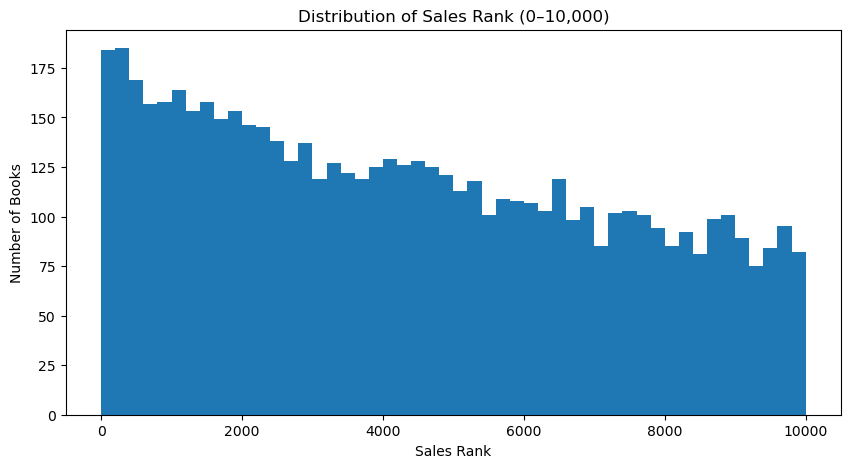

In [8]:
## Distribution of Amazon Sales Rank

plt.figure(figsize=(10,5))
plt.hist(df["statistics.sales rank"], bins=50)
plt.title("Distribution of Amazon Sales Rank")
plt.xlabel("Sales Rank")
plt.ylabel("Number of Books")
plt.show()

plt.figure(figsize=(10,5))
plt.hist(df["statistics.sales rank"], bins=50, range=(0,10000))
plt.title("Distribution of Sales Rank (0–10,000)")
plt.xlabel("Sales Rank")
plt.ylabel("Number of Books")
plt.show()


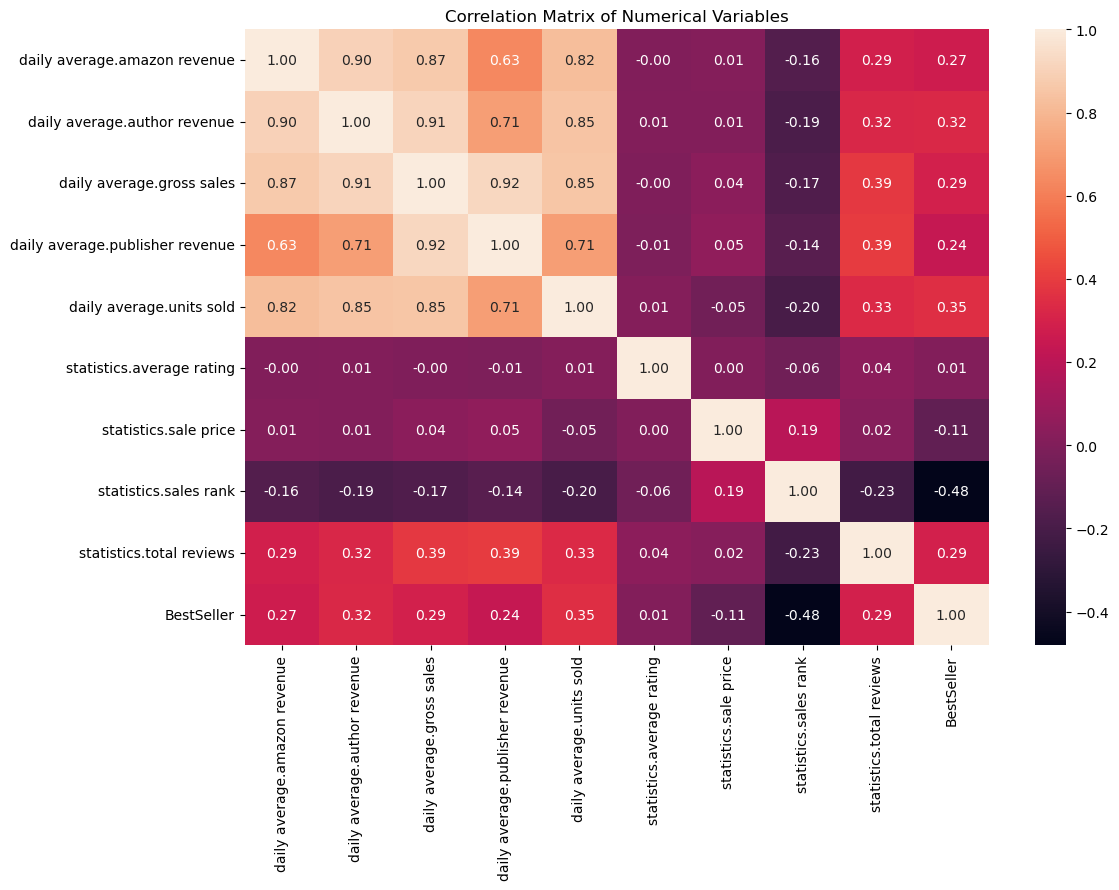

BestSeller                         1.000000
daily average.units sold           0.348056
daily average.author revenue       0.323436
statistics.total reviews           0.293715
daily average.gross sales          0.293240
daily average.amazon revenue       0.270493
daily average.publisher revenue    0.236261
statistics.average rating          0.007968
statistics.sale price             -0.108989
statistics.sales rank             -0.481442
Name: BestSeller, dtype: float64


In [9]:
## Correlation Matrix of Numerical Variables

numerical_columns = [
    "daily average.amazon revenue",
    "daily average.author revenue",
    "daily average.gross sales",
    "daily average.publisher revenue",
    "daily average.units sold",
    "statistics.average rating",
    "statistics.sale price",
    "statistics.sales rank",
    "statistics.total reviews",
    "BestSeller"
]

plt.figure(figsize=(12,8))
corr = df[numerical_columns].corr()

sns.heatmap(corr, annot=True, fmt=".2f")
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

print(
    df[
        numerical_columns
    ].corr()["BestSeller"].sort_values(ascending=False)
)


In [10]:
## Comparison of Best Sellers and Non-Best Sellers

numerical_features = [
    "daily average.amazon revenue",
    "daily average.author revenue",
    "daily average.gross sales",
    "daily average.publisher revenue",
    "daily average.units sold",
    "statistics.average rating",
    "statistics.sale price",
    "statistics.total reviews"
]

comparison = df.groupby("BestSeller")[numerical_features].mean().T
comparison.columns = ["Not Best Seller", "Best Seller"]
print(comparison)


                                 Not Best Seller  Best Seller
daily average.amazon revenue           11.510298   212.118233
daily average.author revenue           13.305937   226.730686
daily average.gross sales              51.609108   801.663348
daily average.publisher revenue        26.792873   362.814429
daily average.units sold                8.209880   170.433819
statistics.average rating               4.156693     4.180137
statistics.sale price                   7.048089     4.997182
statistics.total reviews               82.400580   489.387830


                  total_books  bestsellers  bestseller_percentage
genre                                                            
fiction                   733          248                  33.83
genre fiction            8903         2512                  28.22
nonfiction              14161          715                   5.05
children                 2541           88                   3.46
comics                    568            3                   0.53
foreign language          121            0                   0.00


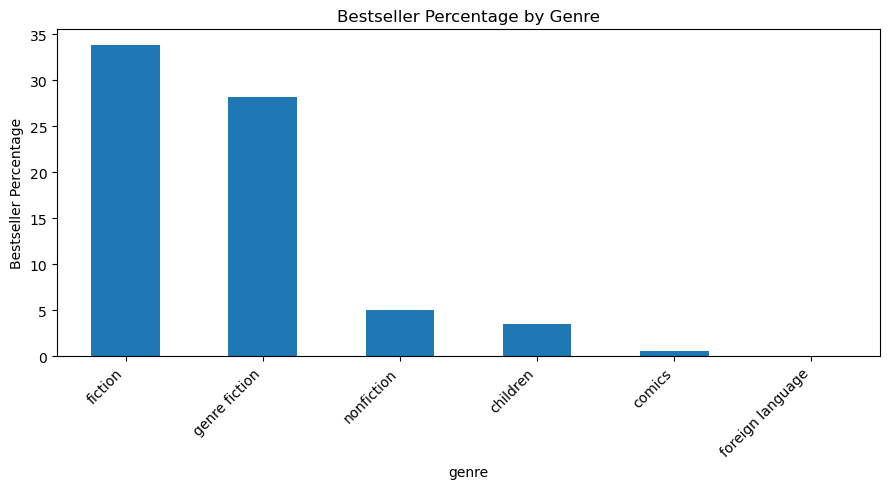

In [11]:
## Bestseller distribution by genre and publisher type

genre_analysis = (
    df.groupby("genre")["BestSeller"]
      .agg(total_books="count", bestsellers="sum")
      .assign(
          bestseller_percentage=lambda x:
          (x["bestsellers"] / x["total_books"] * 100).round(2)
      )
      .sort_values("bestseller_percentage", ascending=False)
)

print(genre_analysis)

genre_analysis["bestseller_percentage"].plot(kind="bar", figsize=(9,5))
plt.title("Bestseller Percentage by Genre")
plt.ylabel("Bestseller Percentage")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


                total_books  bestsellers  bestseller_percentage
publisher.type                                                 
amazon                  423          187                  44.21
indie                  5946         1147                  19.29
big five               7309         1333                  18.24
single author          3608          323                   8.95
small/medium           9741          576                   5.91


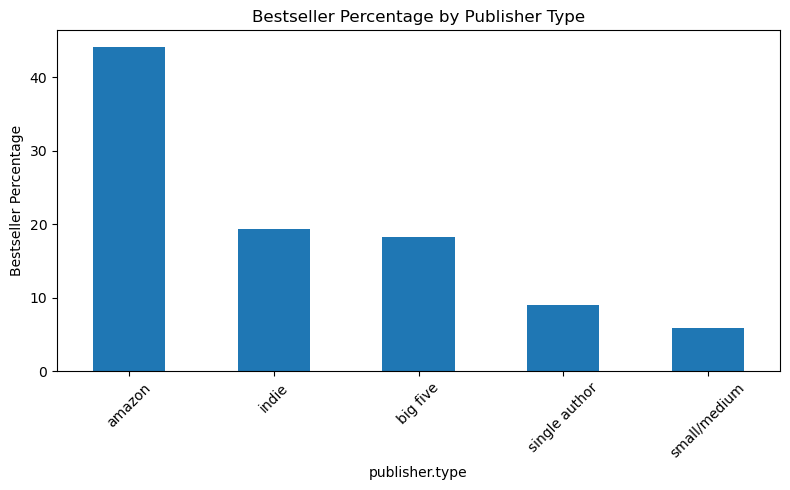

In [12]:
#Publisher-type analysis
publisher_analysis = (
    df.groupby("publisher.type")["BestSeller"]
      .agg(total_books="count", bestsellers="sum")
      .assign(
          bestseller_percentage=lambda x:
          (x["bestsellers"] / x["total_books"] * 100).round(2)
      )
      .sort_values("bestseller_percentage", ascending=False)
)

print(publisher_analysis)

publisher_analysis["bestseller_percentage"].plot(kind="bar", figsize=(8,5))
plt.title("Bestseller Percentage by Publisher Type")
plt.ylabel("Bestseller Percentage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:
## Feature selection using p-values

#Candidate variables are genre, publisher type, average rating, sale price and total reviews.
#Sales rank is excluded because it defines the target.

import statsmodels.api as sm

df_selection = df.copy()

df_selection["genre"] = df_selection["genre"].replace(
    "foreign language", "other"
)

sold_counts = df_selection["sold by"].value_counts()
rare_sellers = sold_counts[sold_counts < 10].index

df_selection["sold by"] = df_selection["sold by"].replace(
    rare_sellers, "Other"
)

df_pvalue = df_selection[
    df_selection["genre"] != "other"
].copy()

features_pvalue = [
    "genre",
    "publisher.type",
    "statistics.average rating",
    "statistics.sale price",
    "statistics.total reviews"
]

X_pvalue = pd.get_dummies(
    df_pvalue[features_pvalue],
    columns=["genre", "publisher.type"],
    drop_first=True
).astype(float)

X_pvalue = sm.add_constant(X_pvalue)
y_pvalue = df_pvalue["BestSeller"]

logit_model = sm.Logit(y_pvalue, X_pvalue)
result = logit_model.fit(maxiter=200, disp=True)

print(result.summary())


Optimization terminated successfully.
         Current function value: 0.280591
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:             BestSeller   No. Observations:                26906
Model:                          Logit   Df Residuals:                    26894
Method:                           MLE   Df Model:                           11
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                  0.2827
Time:                        12:00:31   Log-Likelihood:                -7549.6
converged:                       True   LL-Null:                       -10525.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -2.7150      0.193    -14.094      0.000

In [14]:
#Final selected features
selected_features = [
    "genre",
    "publisher.type",
    "statistics.sale price",
    "statistics.total reviews"
]

print("Selected features:")
for feature in selected_features:
    print("-", feature)


Selected features:
- genre
- publisher.type
- statistics.sale price
- statistics.total reviews


In [15]:
## Prepare modelling data

#Categorical predictors are converted into dummy variables. The data are split using stratification
#so that the minority class remains represented in both training and testing sets.
    
#Train/test split and scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = pd.get_dummies(
    df[selected_features],
    columns=["genre", "publisher.type"],
    drop_first=True
).astype(float)

y = df["BestSeller"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 21621
Testing records: 5406


In [16]:
## Logistic regression from scratch

#The model uses the sigmoid function, gradient descent and binary cross-entropy/log-loss.

class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            predictions = self.sigmoid(linear_model)

            dw = (1 / n_samples) * np.dot(
                X.T, predictions - y
            )
            db = (1 / n_samples) * np.sum(
                predictions - y
            )

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            eps = 1e-15
            loss = -(1 / n_samples) * np.sum(
                y * np.log(predictions + eps) +
                (1 - y) * np.log(1 - predictions + eps)
            )

            self.loss_history.append(loss)

    def predict_probability(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self.sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_probability(X)
        return (probabilities >= threshold).astype(int)


In [17]:
#Initial and improved models
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

model = LogisticRegressionScratch(
    learning_rate=0.01,
    n_iterations=1000
)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled, threshold=0.5)

print("Initial model")
print("Accuracy :", round(float(accuracy_score(y_test, y_pred)), 4))
print("Precision:", round(float(precision_score(y_test, y_pred, zero_division=0)), 4))
print("Recall   :", round(float(recall_score(y_test, y_pred, zero_division=0)), 4))
print("F1-score :", round(float(f1_score(y_test, y_pred, zero_division=0)), 4))

improved_model = LogisticRegressionScratch(
    learning_rate=0.05,
    n_iterations=2000
)
improved_model.fit(X_train_scaled, y_train)

y_pred_improved = improved_model.predict(
    X_test_scaled, threshold=0.5
)

print("\nImproved model")
print("Accuracy :", round(float(accuracy_score(y_test, y_pred_improved)), 4))
print("Precision:", round(float(precision_score(y_test, y_pred_improved, zero_division=0)), 4))
print("Recall   :", round(float(recall_score(y_test, y_pred_improved, zero_division=0)), 4))
print("F1-score :", round(float(f1_score(y_test, y_pred_improved, zero_division=0)), 4))


Initial model
Accuracy : 0.8827
Precision: 0.8435
Recall   : 0.136
F1-score : 0.2343

Improved model
Accuracy : 0.8873
Precision: 0.7549
Recall   : 0.216
F1-score : 0.3359


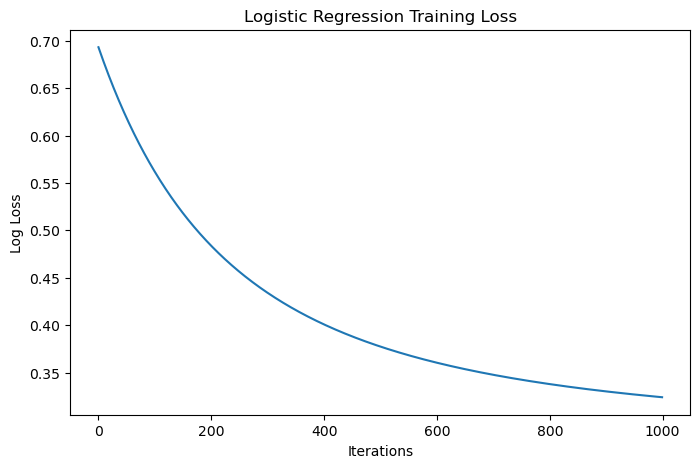

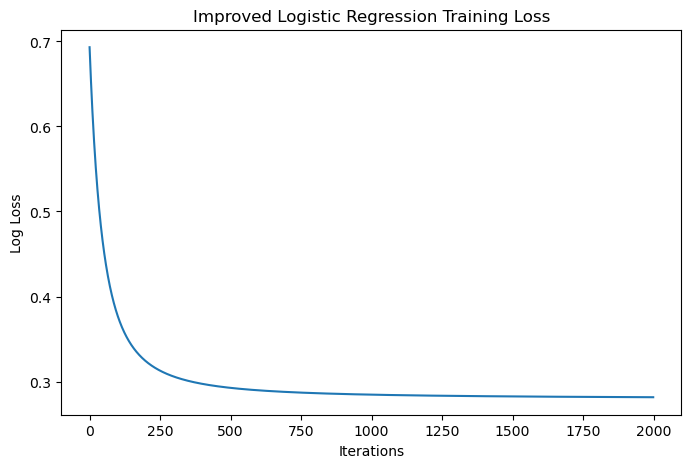

In [18]:
#Training loss
plt.figure(figsize=(8,5))
plt.plot(model.loss_history)
plt.xlabel("Iterations")
plt.ylabel("Log Loss")
plt.title("Logistic Regression Training Loss")
plt.show()

plt.figure(figsize=(8,5))
plt.plot(improved_model.loss_history)
plt.xlabel("Iterations")
plt.ylabel("Log Loss")
plt.title("Improved Logistic Regression Training Loss")
plt.show()


In [19]:
## Threshold optimisation

#The threshold is selected using the highest F1-score rather than the highest accuracy.

y_probability = improved_model.predict_probability(X_test_scaled)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_results = []

for threshold in thresholds:
    pred = (y_probability >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_results)
print(threshold_results.round(4))

best_row = threshold_results.loc[
    threshold_results["F1-score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\nBest threshold:", best_threshold)
print("Best F1-score:", round(float(best_row["F1-score"]), 4))


   Threshold  Accuracy  Precision  Recall  F1-score
0        0.3    0.8663     0.4934  0.5217    0.5072
1        0.4    0.8896     0.6812  0.3058    0.4221
2        0.5    0.8873     0.7549  0.2160    0.3359
3        0.6    0.8846     0.7834  0.1725    0.2828
4        0.7    0.8835     0.8487  0.1417    0.2428

Best threshold: 0.3
Best F1-score: 0.5072


Final Model Evaluation
----------------------
Accuracy : 0.8663
Precision: 0.4934
Recall   : 0.5217
F1-score : 0.5072

Final Confusion Matrix:
[[4311  382]
 [ 341  372]]


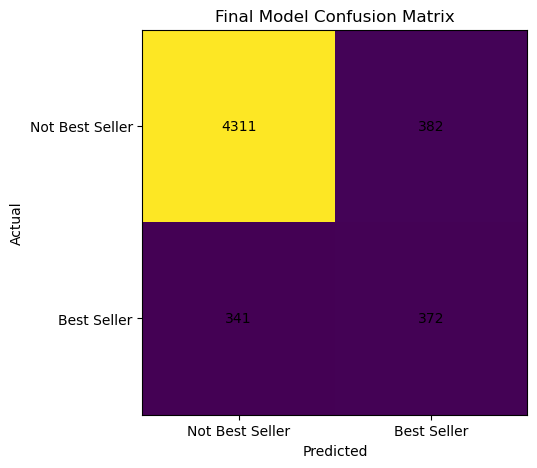

In [20]:
#Final evaluation and confusion matrix
y_pred_final = (
    y_probability >= best_threshold
).astype(int)

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(
    y_test, y_pred_final, zero_division=0
)
final_recall = recall_score(
    y_test, y_pred_final, zero_division=0
)
final_f1 = f1_score(
    y_test, y_pred_final, zero_division=0
)

print("Final Model Evaluation")
print("----------------------")
print("Accuracy :", round(float(final_accuracy), 4))
print("Precision:", round(float(final_precision), 4))
print("Recall   :", round(float(final_recall), 4))
print("F1-score :", round(float(final_f1), 4))

final_cm = confusion_matrix(y_test, y_pred_final)
print("\nFinal Confusion Matrix:")
print(final_cm)

plt.figure(figsize=(6,5))
plt.imshow(final_cm)
plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ["Not Best Seller", "Best Seller"])
plt.yticks([0,1], ["Not Best Seller", "Best Seller"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, final_cm[i,j], ha="center", va="center")

plt.show()


In [21]:

## Feature weights

#The absolute weight provides a simple indication of which encoded variables have the strongest
#influence on the scratch model's linear score. It should not be interpreted as causal importance.

feature_weights = pd.DataFrame({
    "Feature": X.columns,
    "Weight": improved_model.weights
})

feature_weights["Absolute Weight"] = (
    feature_weights["Weight"].abs()
)

feature_weights = feature_weights.sort_values(
    "Absolute Weight", ascending=False
)

print(feature_weights)


                         Feature    Weight  Absolute Weight
1       statistics.total reviews  1.295380         1.295380
5            genre_genre fiction  0.841128         0.841128
0          statistics.sale price -0.405648         0.405648
10   publisher.type_small/medium -0.394486         0.394486
3                  genre_fiction  0.330907         0.330907
9   publisher.type_single author -0.175831         0.175831
2                   genre_comics -0.150861         0.150861
4         genre_foreign language -0.105249         0.105249
8           publisher.type_indie  0.075633         0.075633
6               genre_nonfiction  0.005450         0.005450
7        publisher.type_big five -0.000454         0.000454
